In [ ]:
import pandas as pd
df = pd.read_csv("loan_approval_dataset.csv")
print(df.shape)
print(df.head())
print(df.columns.tolist())

(4269, 13)
   loan_id   no_of_dependents      education  self_employed   income_annum  \
0        1                  2       Graduate             No        9600000   
1        2                  0   Not Graduate            Yes        4100000   
2        3                  3       Graduate             No        9100000   
3        4                  3       Graduate             No        8200000   
4        5                  5   Not Graduate            Yes        9800000   

    loan_amount   loan_term   cibil_score   residential_assets_value  \
0      29900000          12           778                    2400000   
1      12200000           8           417                    2700000   
2      29700000          20           506                    7100000   
3      30700000           8           467                   18200000   
4      24200000          20           382                   12400000   

    commercial_assets_value   luxury_assets_value   bank_asset_value  \
0              

# Part 1: Data Preparation


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Column names ke spaces hatao ---
df.columns = df.columns.str.strip()

# --- Text columns ke andar ke spaces bhi hatao ---
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# --- Missing values check ---
print("Missing values:\n", df.isnull().sum())

# --- Duplicates check aur remove ---
print("\nDuplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# --- loan_id model ke liye useless hai ---
df = df.drop(columns=["loan_id"])

# --- Target ko numeric banao (Approved = 1, Rejected = 0) ---
df["loan_status"] = df["loan_status"].map({"Approved": 1, "Rejected": 0})

# --- Final check ---
print("\nShape after cleaning:", df.shape)
print("\nTarget distribution:\n", df["loan_status"].value_counts(normalize=True))
print("\nData types:\n", df.dtypes)

Missing values:
 loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Duplicates: 0

Shape after cleaning: (4269, 12)

Target distribution:
 loan_status
1    0.62216
0    0.37784
Name: proportion, dtype: float64

Data types:
 no_of_dependents             int64
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                  int64
dty

## Part 1 (continued): Feature Engineering, Selection & Scaling

### 1.1 Feature Engineering

In [ ]:
# --- Categorical columns ko numeric banao ---
df["education"] = df["education"].map({"Graduate": 1, "Not Graduate": 0})
df["self_employed"] = df["self_employed"].map({"Yes": 1, "No": 0})

# --- Naye features banao ---
asset_cols = ["residential_assets_value", "commercial_assets_value",
              "luxury_assets_value", "bank_asset_value"]

df["total_assets"] = df[asset_cols].sum(axis=1)
df["loan_to_income"] = df["loan_amount"] / df["income_annum"]
df["assets_to_loan"] = df["total_assets"] / df["loan_amount"]
df["income_per_dependent"] = df["income_annum"] / (df["no_of_dependents"] + 1)
df["monthly_payment"] = df["loan_amount"] / (df["loan_term"] * 12)

print("Shape:", df.shape)
df.head()

Shape: (4269, 17)


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,total_assets,loan_to_income,assets_to_loan,income_per_dependent,monthly_payment
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1,50700000,3.114583,1.695652,3.200000e+06,207638.888889
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0,17000000,2.975610,1.393443,4.100000e+06,127083.333333
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,57700000,3.263736,1.942761,2.275000e+06,123750.000000
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,52700000,3.743902,1.716612,2.050000e+06,319791.666667
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0,55000000,2.469388,2.272727,1.633333e+06,100833.333333


### 1.2 Correlation Heatmap

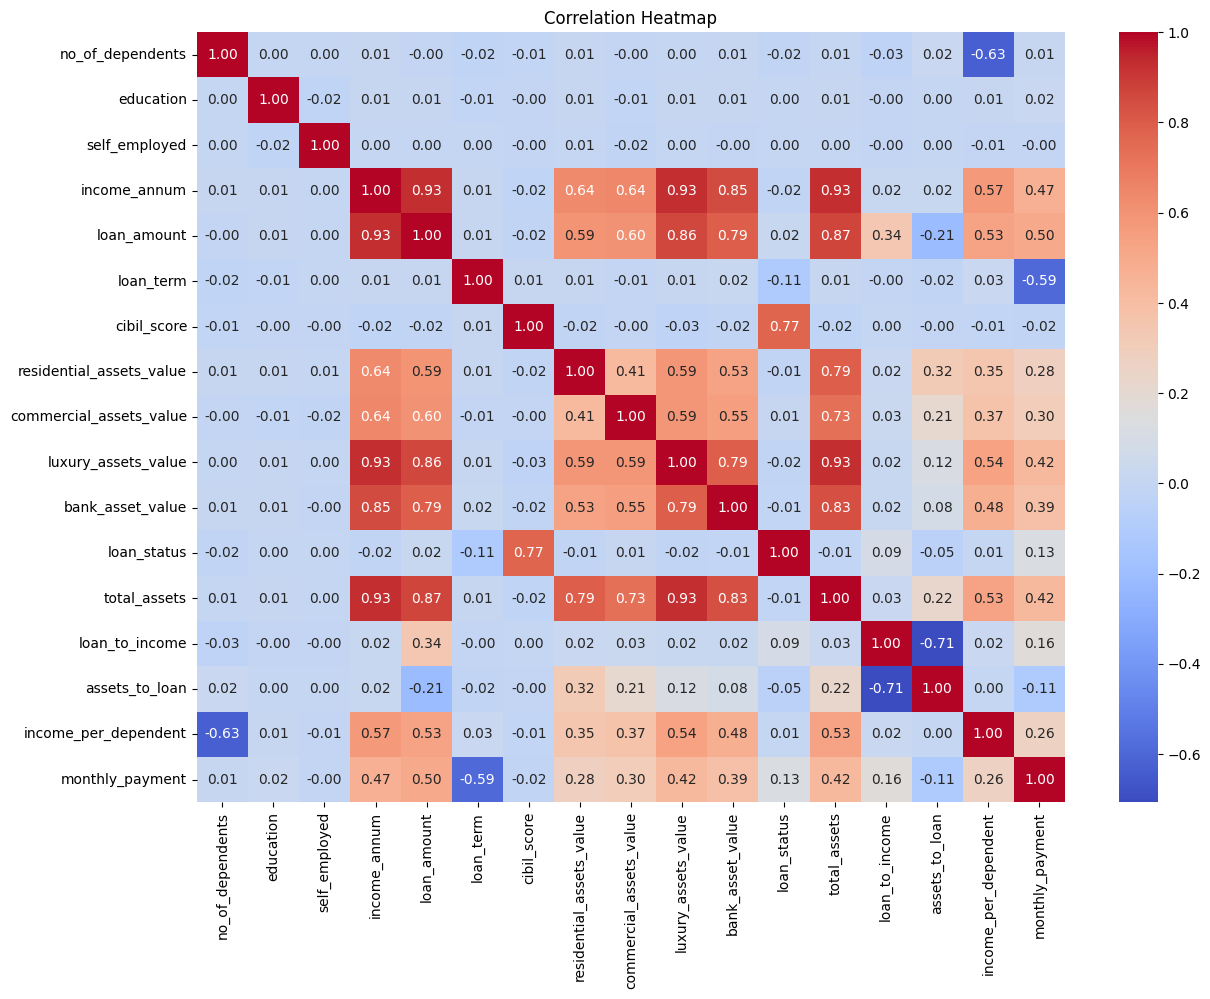

In [ ]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### 1.3 Train/Test Split & Missing Values Handling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X = df.drop(columns=["loan_status"])
y = df["loan_status"]

# Pehle split, phir scaling (taake data leakage na ho)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Missing values handling (is dataset mein 0 hain, lekin pipeline reusable rahe)
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (3415, 16) | Test: (854, 16)


### 1.4 Feature Selection

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X_train, y_train)

scores = pd.DataFrame({
    "Feature": X_train.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False)
print(scores)

selected_features = X_train.columns[selector.get_support()].tolist()
print("\nSelected features:", selected_features)

X_train = X_train[selected_features]
X_test = X_test[selected_features]
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)

                     Feature        Score
6                cibil_score  4851.784474
15           monthly_payment    49.243014
5                  loan_term    40.015158
12            loan_to_income    32.382007
13            assets_to_loan     7.891158
0           no_of_dependents     1.600123
3               income_annum     1.561234
9        luxury_assets_value     1.405390
4                loan_amount     0.588964
11              total_assets     0.516645
10          bank_asset_value     0.225302
2              self_employed     0.208975
7   residential_assets_value     0.207383
1                  education     0.121754
8    commercial_assets_value     0.093535
14      income_per_dependent     0.004256

Selected features: ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'luxury_assets_value', 'total_assets', 'loan_to_income', 'assets_to_loan', 'monthly_payment']

Train: (3415, 10) | Test: (854, 10)


### 1.5 Data Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=selected_features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=selected_features)

print(X_train_scaled.describe().loc[["mean", "std"]].round(2))

      no_of_dependents  income_annum  loan_amount  loan_term  cibil_score  \
mean              -0.0           0.0         -0.0        0.0         -0.0   
std                1.0           1.0          1.0        1.0          1.0   

      luxury_assets_value  total_assets  loan_to_income  assets_to_loan  \
mean                 -0.0           0.0             0.0             0.0   
std                   1.0           1.0             1.0             1.0   

      monthly_payment  
mean             -0.0  
std               1.0  


## Part 2: Model Development

### 2.1 Training all models

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Scaled data SVM ke liye, baqi models ke liye original (dono chalte hain)
models = {
    "Random Forest": (RandomForestClassifier(random_state=42), False),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), False),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42), False),
    "XGBoost": (XGBClassifier(random_state=42, eval_metric="logloss"), False),
    "SVM": (SVC(probability=True, random_state=42), True),
}

results = []
trained_models = {}

for name, (model, needs_scaling) in models.items():
    Xtr = X_train_scaled if needs_scaling else X_train
    Xte = X_test_scaled if needs_scaling else X_test

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    y_proba = model.predict_proba(Xte)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).round(4)
print(results_df.to_string(index=False))

            Model  Accuracy  Precision  Recall     F1  ROC-AUC
    Decision Tree    1.0000     1.0000  1.0000 1.0000   1.0000
Gradient Boosting    1.0000     1.0000  1.0000 1.0000   1.0000
          XGBoost    0.9988     0.9981  1.0000 0.9991   1.0000
    Random Forest    0.9977     0.9962  1.0000 0.9981   1.0000
              SVM    0.9614     0.9577  0.9812 0.9693   0.9945


### 2.2 Sanity Check (Perfect Score Investigation)

In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text

# Sirf cibil_score se ek chhota sa tree (depth=1)
stump = DecisionTreeClassifier(max_depth=1, random_state=42)
stump.fit(X_train[["cibil_score"]], y_train)

print("Stump accuracy (sirf cibil_score):",
      round(stump.score(X_test[["cibil_score"]], y_test), 4))
print(export_text(stump, feature_names=["cibil_score"]))

# Decision Tree ki feature importance
dt = trained_models["Decision Tree"]
print(pd.Series(dt.feature_importances_, index=X_train.columns)
      .sort_values(ascending=False).round(4))

Stump accuracy (sirf cibil_score): 0.9672
|--- cibil_score <= 549.50
|   |--- class: 0
|--- cibil_score >  549.50
|   |--- class: 1

cibil_score            0.8104
loan_to_income         0.0909
loan_term              0.0838
assets_to_loan         0.0149
income_annum           0.0000
no_of_dependents       0.0000
luxury_assets_value    0.0000
loan_amount            0.0000
total_assets           0.0000
monthly_payment        0.0000
dtype: float64


## Part 3: Model Optimization

### 3.1 Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for name, (model, needs_scaling) in models.items():
    Xtr = X_train_scaled if needs_scaling else X_train
    scores = cross_val_score(model, Xtr, y_train, cv=skf, scoring="f1")
    cv_results.append({
        "Model": name,
        "CV Mean F1": scores.mean(),
        "CV Std": scores.std(),
    })

cv_df = pd.DataFrame(cv_results).sort_values("CV Mean F1", ascending=False).round(4)
print(cv_df.to_string(index=False))

            Model  CV Mean F1  CV Std
    Decision Tree      1.0000  0.0000
Gradient Boosting      0.9998  0.0005
    Random Forest      0.9986  0.0009
          XGBoost      0.9984  0.0016
              SVM      0.9656  0.0069


### 3.2 Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5],
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3],
    },
    "Decision Tree": {
        "max_depth": [3, 5, 10, None],
        "min_samples_split": [2, 5, 10],
    },
    "SVM": {
        "C": [0.1, 1, 10],
        "kernel": ["rbf", "linear"],
    },
}

tuned_results = []
best_estimators = {}

for name, grid in param_grids.items():
    model, needs_scaling = models[name]
    Xtr = X_train_scaled if needs_scaling else X_train
    Xte = X_test_scaled if needs_scaling else X_test

    gs = GridSearchCV(model, grid, cv=skf, scoring="f1", n_jobs=-1)
    gs.fit(Xtr, y_train)

    best = gs.best_estimator_
    y_pred = best.predict(Xte)
    best_estimators[name] = best

    tuned_results.append({
        "Model": name,
        "Best CV F1": gs.best_score_,
        "Test F1": f1_score(y_test, y_pred),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Best Params": gs.best_params_,
    })
    print(f"{name} done -> {gs.best_params_}")

tuned_df = pd.DataFrame(tuned_results).sort_values("Test F1", ascending=False)
print()
print(tuned_df.drop(columns="Best Params").round(4).to_string(index=False))

Random Forest done -> {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Gradient Boosting done -> {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Decision Tree done -> {'max_depth': 5, 'min_samples_split': 2}
SVM done -> {'C': 10, 'kernel': 'rbf'}

            Model  Best CV F1  Test F1  Test Accuracy
Gradient Boosting      0.9998   1.0000         1.0000
    Decision Tree      1.0000   1.0000         1.0000
    Random Forest      0.9988   0.9991         0.9988
              SVM      0.9729   0.9804         0.9754


### 3.3 Feature Importance Analysis

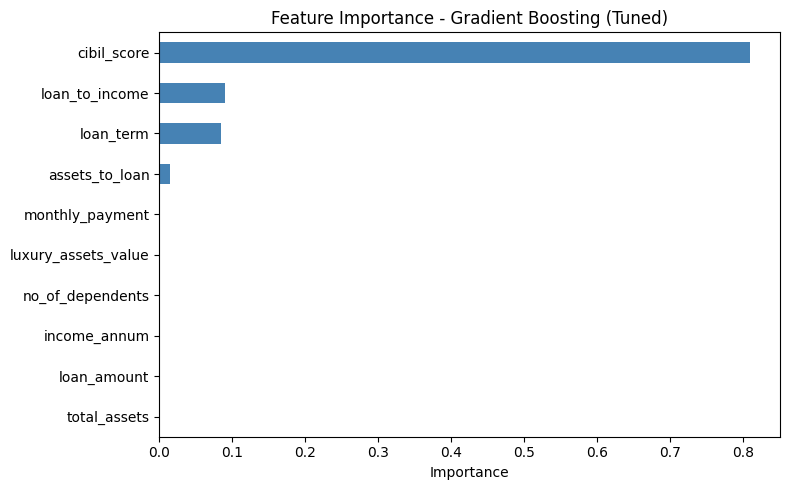

cibil_score            0.8106
loan_to_income         0.0903
loan_term              0.0847
assets_to_loan         0.0143
monthly_payment        0.0000
luxury_assets_value    0.0000
income_annum           0.0000
no_of_dependents       0.0000
loan_amount           -0.0000
total_assets          -0.0000
dtype: float64


In [ ]:
best_gb = best_estimators["Gradient Boosting"]

importance = pd.Series(best_gb.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="steelblue")
plt.title("Feature Importance - Gradient Boosting (Tuned)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).round(4))

Part 4: Save the Best Model

In [ ]:
import joblib
import pickle
import os

os.makedirs("models", exist_ok=True)

best_model = best_estimators["Gradient Boosting"]

# --- Joblib se save ---
joblib.dump(best_model, "models/best_model.joblib")

# --- Pickle se save ---
with open("models/best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

# --- Scaler aur selected features bhi save karo (Streamlit mein kaam aayenge) ---
joblib.dump(scaler, "models/scaler.joblib")
joblib.dump(selected_features, "models/selected_features.joblib")

# --- Load karke verify karo ---
loaded_joblib = joblib.load("models/best_model.joblib")
with open("models/best_model.pkl", "rb") as f:
    loaded_pickle = pickle.load(f)

print("Joblib model F1:", round(f1_score(y_test, loaded_joblib.predict(X_test)), 4))
print("Pickle model F1:", round(f1_score(y_test, loaded_pickle.predict(X_test)), 4))
print("\nSaved files:", os.listdir("models"))

Joblib model F1: 1.0
Pickle model F1: 1.0

Saved files: ['scaler.joblib', 'best_model.pkl', 'selected_features.joblib', 'best_model.joblib']


In [ ]:
import shutil
from google.colab import files

shutil.make_archive("models", "zip", "models")
files.download("models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Part 5: Project Documentation

### 1. Dataset
- **Name:** Loan Approval Prediction Dataset (Kaggle, by Archit Sharma)
- **Size:** 4,269 rows, 13 columns (12 after dropping `loan_id`)
- **Target:** `loan_status` (Approved = 1, Rejected = 0), 62.2% Approved / 37.8% Rejected
- **Features:** dependents, education, self-employment, annual income, loan amount, loan term, CIBIL score, and four asset values
- **Quality:** 0 missing values, 0 duplicates

### 2. Workflow
1. Imported data, stripped extra spaces from column names, checked missing values and duplicates
2. Encoded categorical columns (education, self_employed)
3. **Feature Engineering:** created total_assets, loan_to_income, assets_to_loan, income_per_dependent, monthly_payment
4. 80/20 stratified train/test split, median imputer (reusable for missing values)
5. **Feature Selection:** SelectKBest (f_classif, k=10)
6. **Scaling:** StandardScaler (fitted on train only, to avoid leakage)
7. Trained 5 models, 5-fold cross validation, GridSearchCV tuning
8. Feature importance analysis, best model saved with Joblib and Pickle
9. Streamlit app for predictions

### 3. Model Selection
Trained Random Forest, Decision Tree, Gradient Boosting, XGBoost and SVM. Compared on Accuracy, Precision, Recall, F1 and ROC-AUC, then validated with 5-fold stratified cross validation and tuned with GridSearchCV (Random Forest, Gradient Boosting, Decision Tree, SVM).
Decision Tree and Gradient Boosting both reached 100% test F1. **Gradient Boosting** was chosen because an ensemble is more stable than a single tree, and its CV std was very low (0.0005).

### 4. Results
| Model | Best CV F1 | Test F1 | Test Accuracy |
|---|---|---|---|
| Gradient Boosting | 0.9998 | 1.0000 | 1.0000 |
| Decision Tree | 1.0000 | 1.0000 | 1.0000 |
| Random Forest | 0.9988 | 0.9991 | 0.9988 |
| SVM | 0.9729 | 0.9804 | 0.9754 |

- Tuning improved SVM the most (F1 0.9693 to 0.9804).
- Feature importance (Gradient Boosting): cibil_score 81%, loan_to_income 9%, loan_term 8.5%, assets_to_loan 1.4%; the other features were close to 0.
- Correlation of cibil_score with loan_status was 0.77, the highest of all features.

### 5. Limitations
- Approval depends mostly on `cibil_score` (threshold about 550). A one-split tree gives 96.7% accuracy, so near-perfect scores reflect a simple dataset, not necessarily real-world performance.
- The dataset appears synthetic, so results may not transfer to real banking data.
- Several features are highly correlated (income, loan amount, assets), which is multicollinearity.
- SelectKBest with fixed k=10 kept some low-scoring features.
- Class imbalance is mild (62/38) and was not resampled.
- XGBoost was trained but not tuned (optional in the task).

### 6. Future Improvements
- Test on a larger, real-world loan dataset
- Tune XGBoost and try RandomizedSearchCV or Optuna
- Try SMOTE or class weights for imbalance
- Add model explainability (SHAP)
- Wrap everything in a single sklearn Pipeline for deployment
- Deploy the Streamlit app online (Streamlit Community Cloud)